# 泰坦尼克号生存分析

> **一句话结论**：生还率主要由**性别**和**舱位**决定——女性生还率 74.2% 是男性 18.9% 的约 **4 倍**；头等舱 63.0% 是三等舱 24.2% 的 **2.6 倍**；卡方检验显示两个差异都高度显著（p < 1e-20）。在控制年龄、票价、家庭规模后，男性生还的优势比仅 0.07（即女性约为男性的 14 倍）。

本 notebook 分四步：**数据概览 → 描述统计与可视化 → 假设检验 → 建模解释**。
数据：Kaggle Titanic 训练集，891 行 × 12 列。

## 研究问题

| 编号 | 问题 | 方法 |
|---|---|---|
| Q1 | 性别、舱位、年龄与生还率的关系有多大？ | 描述统计 + 可视化 |
| Q2 | 这些差异是抽样波动，还是真的显著？ | 卡方检验 / t 检验 |
| Q3 | 控制其他变量后，每个因素的独立影响有多大？ | logistic 回归（OR） |

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, roc_curve
from sklearn.utils import resample

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

df = pd.read_csv("data/titanic.csv")
print("形状:", df.shape)
df.head()

形状: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. 数据概览

先看规模、字段类型、缺失率和目标变量分布。**缺失率决定了后面哪些变量能用**。

In [2]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "缺失数": df.isna().sum(),
    "缺失率(%)": (df.isna().mean() * 100).round(1),
})
display(overview)

print("整体生还率: %.1f%% (%d / %d)" % (df.Survived.mean() * 100, df.Survived.sum(), len(df)))
df.Survived.value_counts().rename({0: "死亡", 1: "生还"}).to_frame("人数")

,dtype,缺失数,缺失率(%)
PassengerId,int64,0,0.0
Survived,int64,0,0.0
Pclass,int64,0,0.0
Name,str,0,0.0
Sex,str,0,0.0
Age,float64,177,19.9
SibSp,int64,0,0.0
Parch,int64,0,0.0
Ticket,str,0,0.0
Fare,float64,0,0.0


整体生还率: 38.4% (342 / 891)


,人数
Survived,
死亡,549
生还,342


**观察**：`Age` 缺失 19.9%、`Cabin` 缺失 77.1%、`Embarked` 缺失 2 条。
- `Cabin` 缺失太多，不适合做主变量（后面只讨论，不进模型）
- `Age` 用中位数填充，`Embarked` 用众数填充
- 类别分布没有极端不平衡（38.4% / 61.6%），准确率这个指标还能用，但仍需看 AUC

## 2. 描述统计与可视化

### 2.1 性别与舱位

In [3]:
by_sex = df.groupby("Sex")["Survived"].agg(["mean", "count"]).rename(columns={"mean": "生还率"})
by_sex["生还率"] = (by_sex["生还率"] * 100).round(1)
display(by_sex)

by_pclass = df.groupby("Pclass")["Survived"].agg(["mean", "count"]).rename(columns={"mean": "生还率"})
by_pclass["生还率"] = (by_pclass["生还率"] * 100).round(1)
display(by_pclass)

pivot = df.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean") * 100
pivot.round(1)

,生还率,count
Sex,,
female,74.2,314
male,18.9,577


,生还率,count
Pclass,,
1,63.0,216
2,47.3,184
3,24.2,491


Pclass,1,2,3
Sex,,,
female,96.8,92.1,50.0
male,36.9,15.7,13.5


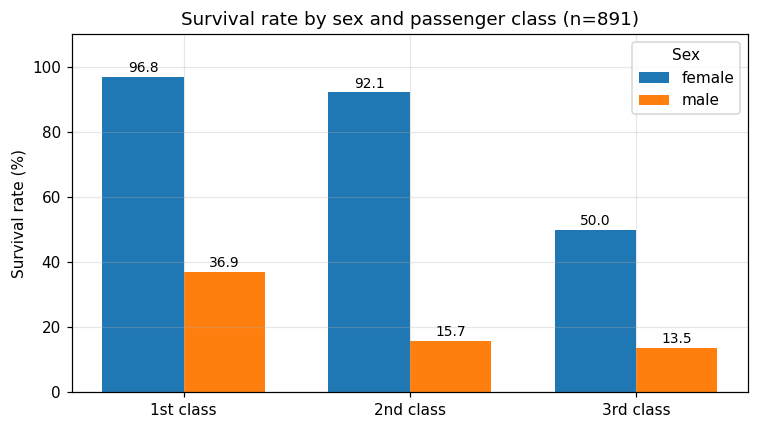

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
plot_df = df.groupby(["Pclass", "Sex"])["Survived"].mean().unstack() * 100
x = np.arange(len(plot_df))
w = 0.36
for i, sex in enumerate(plot_df.columns):
    bars = ax.bar(x + (i - 0.5) * w, plot_df[sex], w, label=sex)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5,
                f"{b.get_height():.1f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(["1st class", "2nd class", "3rd class"])
ax.set_ylabel("Survival rate (%)")
ax.set_ylim(0, 110)
ax.set_title("Survival rate by sex and passenger class (n=891)")
ax.legend(title="Sex")
fig.tight_layout()
fig.savefig("images/survival_by_sex_pclass.png", bbox_inches="tight")
plt.show()

### 2.2 年龄与票价

年龄缺失 19.9%，先看有值的那部分；票价用对数刻度看分布。

有年龄记录的乘客: 714 人
生还者平均年龄 28.3 岁，遇难者平均年龄 30.6 岁


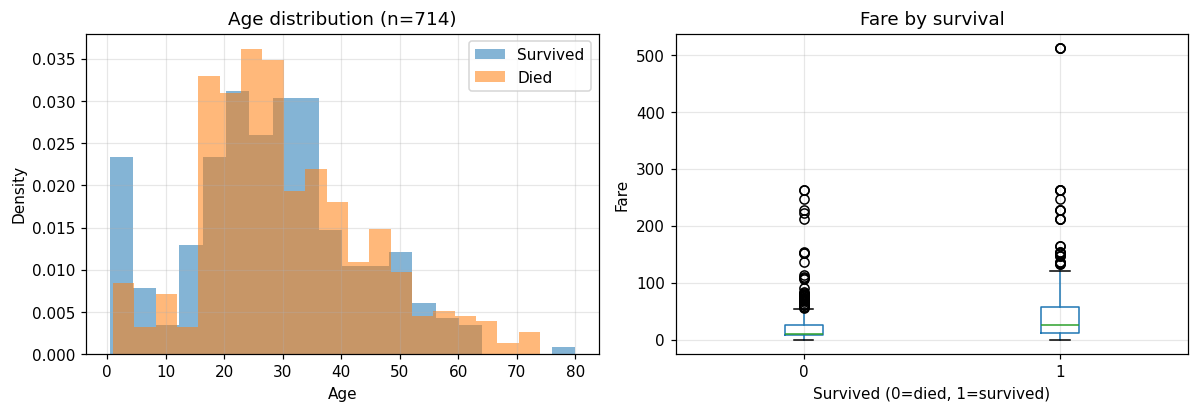

In [5]:
age = df.dropna(subset=["Age"])
print("有年龄记录的乘客:", len(age), "人")
print("生还者平均年龄 %.1f 岁，遇难者平均年龄 %.1f 岁" % (
    age.loc[age.Survived == 1, "Age"].mean(),
    age.loc[age.Survived == 0, "Age"].mean()))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, sub in [("Survived", age[age.Survived == 1]), ("Died", age[age.Survived == 0])]:
    axes[0].hist(sub["Age"], bins=20, alpha=0.55, label=label, density=True)
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Density")
axes[0].set_title("Age distribution (n=%d)" % len(age))
axes[0].legend()

df.boxplot(column="Fare", by="Survived", ax=axes[1])
axes[1].set_title("Fare by survival")
axes[1].set_xlabel("Survived (0=died, 1=survived)")
axes[1].set_ylabel("Fare")
fig.suptitle("")
fig.tight_layout()
fig.savefig("images/age_distribution.png", bbox_inches="tight")
plt.show()

## 3. 假设检验

描述统计只能说明"样本里有差异"，**检验才能回答"这个差异会不会是抽样波动"**。

- 性别 × 生还：两个分类变量 → 卡方独立性检验
- 舱位 × 生还：同上
- 年龄（连续）× 生还：两组比较 → 独立样本 t 检验

> 注意：p 值小只说明"不太可能纯属偶然"，**不说明差异有多大、更不能说明因果**。

In [6]:
# 性别 × 生还
tab_sex = pd.crosstab(df["Sex"], df["Survived"])
chi2, p, dof, _ = stats.chi2_contingency(tab_sex)
print("性别 × 生还：chi2 = %.1f, dof = %d, p = %.2e" % (chi2, dof, p))
display(tab_sex)

# 舱位 × 生还
tab_pclass = pd.crosstab(df["Pclass"], df["Survived"])
chi2b, pb, dofb, _ = stats.chi2_contingency(tab_pclass)
print("舱位 × 生还：chi2 = %.1f, dof = %d, p = %.2e" % (chi2b, dofb, pb))
display(tab_pclass)

# 年龄 × 生还
t, pt = stats.ttest_ind(age.loc[age.Survived == 1, "Age"], age.loc[age.Survived == 0, "Age"])
print("年龄：生还组 vs 遇难组 t = %.2f, p = %.3f（差异显著但很小）" % (t, pt))

性别 × 生还：chi2 = 260.7, dof = 1, p = 1.20e-58


Survived,0,1
Sex,,
female,81,233
male,468,109


舱位 × 生还：chi2 = 102.9, dof = 2, p = 4.55e-23


Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


年龄：生还组 vs 遇难组 t = -2.07, p = 0.039（差异显著但很小）


**解读**：
- 性别：p ≈ 1e-58，强烈拒绝"性别与生还独立"
- 舱位：p ≈ 1e-23，同样显著
- 年龄：p ≈ 0.039，统计学上显著，但没有实际意义——两组的平均年龄只差 2.3 岁

这说明**显著的变量不一定重要**，要同时看效应量。

## 4. 建模：logistic 回归

Q1、Q2 都是单变量视角。Q3 要回答：**控制住其他变量后，某个因素还剩多少独立影响？**

标签是 0/1，所以用 logistic 回归；结果用**优势比（OR）**表达，可以直接说"几倍"。

特征：性别（男=1）、舱位、年龄（中位数填充）、票价、家庭规模（SibSp + Parch + 1）。

In [7]:
d = df.copy()
d["Age"] = d["Age"].fillna(d["Age"].median())
d["Embarked"] = d["Embarked"].fillna(d["Embarked"].mode()[0])
d["Sex_male"] = (d["Sex"] == "male").astype(int)
d["FamilySize"] = d["SibSp"] + d["Parch"] + 1

features = ["Sex_male", "Pclass", "Age", "Fare", "FamilySize"]
X, y = d[features], d["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]

print("训练集 %d 条，测试集 %d 条" % (len(y_train), len(y_test)))
print("准确率: %.1f%%" % (accuracy_score(y_test, pred) * 100))
print("AUC: %.3f" % roc_auc_score(y_test, prob))
print("混淆矩阵 [[真负, 假正], [假负, 真正]]:")
print(confusion_matrix(y_test, pred))

训练集 712 条，测试集 179 条
准确率: 81.0%
AUC: 0.847
混淆矩阵 [[真负, 假正], [假负, 真正]]:
[[95 15]
 [19 50]]


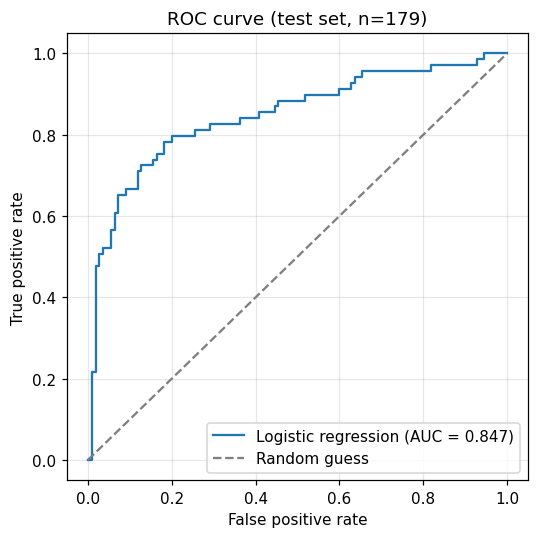

In [8]:
# ROC 曲线
fpr, tpr, _ = roc_curve(y_test, prob)
auc = roc_auc_score(y_test, prob)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, label="Logistic regression (AUC = %.3f)" % auc)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curve (test set, n=%d)" % len(y_test))
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("images/roc_curve.png", bbox_inches="tight")
plt.show()

### 4.1 每个因素的独立影响（优势比 OR）

OR > 1 表示该因素增加生还几率，OR < 1 表示降低。置信区间用 bootstrap 估计（300 次重采样）。

In [9]:
full_model = LogisticRegression(max_iter=1000).fit(X, y)

boot = []
for i in range(300):
    Xb, yb = resample(X, y, random_state=i)
    boot.append(LogisticRegression(max_iter=1000).fit(Xb, yb).coef_[0])
boot = np.array(boot)

rows = []
for i, name in enumerate(features):
    or_ = np.exp(full_model.coef_[0][i])
    lo, hi = np.percentile(np.exp(boot[:, i]), [2.5, 97.5])
    rows.append({"变量": name, "OR": round(or_, 2),
                 "95%CI 下限": round(lo, 2), "95%CI 上限": round(hi, 2)})

or_table = pd.DataFrame(rows)
display(or_table)

,变量,OR,95%CI 下限,95%CI 上限
0,Sex_male,0.07,0.05,0.09
1,Pclass,0.35,0.27,0.46
2,Age,0.96,0.95,0.98
3,Fare,1.00,1.00,1.01
4,FamilySize,0.79,0.69,0.88


**怎么读这张表**：
- `Sex_male` OR = 0.07：**控制了舱位、年龄、票价、家庭规模后**，男性生还的几率只有女性的约 1/14
- `Pclass` OR = 0.35：舱位每降一级，生还几率约为原来的 0.35 倍
- `Age` OR ≈ 0.96：每大 1 岁，生还几率降约 4%（效应很小）
- `Fare` OR ≈ 1.00：票价在控制舱位后几乎没有额外解释力——**它和舱位高度相关**
- `FamilySize` OR = 0.79：家庭越大生还率越低（大家庭逃生更慢）

注意：OR 的置信区间不包含 1 才算稳定显著。`Fare` 的区间跨过 1，说明它不稳健。

## 5. 局限与改进方向

1. **只能解释相关性，不能下因果结论**。数据是历史观测数据，没有实验控制，"女性生还率高"背后还有"妇女儿童优先上救生艇"的制度和执行过程。
2. **幸存者偏差**：样本只包含已知生还情况的乘客。
3. **缺失值处理粗糙**：年龄用中位数填充会压缩方差；`Cabin` 缺失 77% 直接放弃，但它其实包含了很强的阶层信息。
4. **没有交叉验证和调参**：单次 8:2 划分，准确率可能偏高。
5. **可以改进**：从 `Name` 提取称谓（Mr/Mrs/Miss/Master）、家庭规模分箱、5 折交叉验证、随机森林对比。

## 6. 结论

生还率的差异首先是**性别**（女性 74.2% vs 男性 18.9%），其次是**舱位**（头等舱 63.0% vs 三等舱 24.2%）。
两者在控制彼此之后依然显著，说明这不是"性别决定生死"，而是**性别与阶层共同作用**——同一性别下，舱位越低生还率越低（女性：96.8% → 92.1% → 50.0%）。